# Beverage Batch Quality Checks

## Project question

Which practice beverage batches fall outside the example pH and Brix ranges?

I created a small fictional dataset inspired by my quality control work
at Viju Foods. The measurements and limits are for this exercise.

In [2]:
import pandas as pd

batches = pd.DataFrame({
    "batch": ["B01", "B02", "B03", "B04", "B05", "B06"],
    "pH": [3.4, 3.5, 3.9, 3.3, 3.6, 3.2],
    "brix": [11.2, 10.4, 11.1, 11.5, 12.0, 10.7],
})

display(batches)

,batch,pH,brix
0,B01,3.4,11.2
1,B02,3.5,10.4
2,B03,3.9,11.1
3,B04,3.3,11.5
4,B05,3.6,12.0
5,B06,3.2,10.7


In [3]:
batches["pH_in_range"] = batches["pH"].between(3.2, 3.6)
batches["brix_in_range"] = batches["brix"].between(11.0, 11.8)
batches["both_in_range"] = batches["pH_in_range"] & batches["brix_in_range"]

display(batches)

,batch,pH,brix,pH_in_range,brix_in_range,both_in_range
0,B01,3.4,11.2,True,True,True
1,B02,3.5,10.4,True,False,False
2,B03,3.9,11.1,False,True,False
3,B04,3.3,11.5,True,True,True
4,B05,3.6,12.0,True,False,False
5,B06,3.2,10.7,True,False,False


both_in_range
Needs review          4
Within both ranges    2
Name: count, dtype: int64

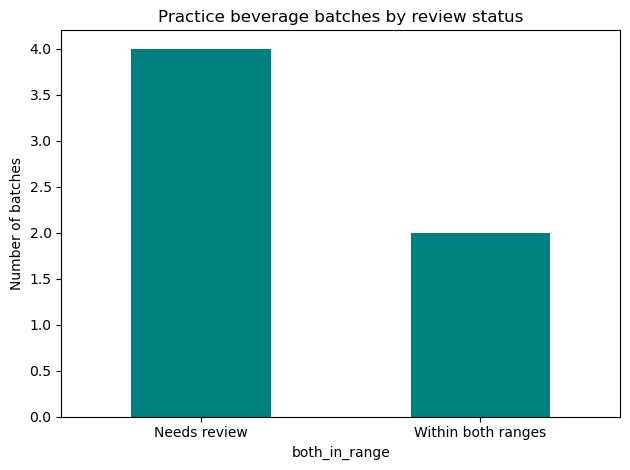

In [4]:
import matplotlib.pyplot as plt

status = batches["both_in_range"].map({
    True: "Within both ranges",
    False: "Needs review",
})

counts = status.value_counts()
display(counts)

counts.plot.bar(color="teal", rot=0)
plt.title("Practice beverage batches by review status")
plt.ylabel("Number of batches")
plt.tight_layout()
plt.show()

## CONCLUSION

#### I used Python to check six fictional beverage batches against example ranges of 3.2–3.6 for pH and 11.0–11.8 °Bx for Brix. Two batches met both criteria, and four were flagged for review.

#### Batch B03 was flagged because its pH of 3.9 exceeded the upper limit of 3.6. The other three flagged batches fell outside the Brix range.